# Benchmark: arcpy_arrow vs. the Spatially Enabled DataFrame

Compares `arcpy_arrow`'s Arrow-based read/write path against the ArcGIS API for Python's
Spatially Enabled DataFrame (SEDF, `arcgis.features.GeoAccessor`) for the same operations:

1. Feature class → (Geo)DataFrame
2. Table → DataFrame
3. (Geo)DataFrame → feature class

Each is timed with `timeit` over a handful of repetitions. Requires the `arcgis` package
(bundled with ArcGIS Pro's Python environment) in addition to `arcpy_arrow`.

In [2]:
import os
import timeit
from pathlib import Path

import arcpy
import pandas as pd
from arcgis.features import GeoAccessor, GeoSeriesAccessor  # noqa: F401  (registers .spatial accessor)

from arcpy_arrow import fc_to_gdf, gdf_to_fc, tbl_to_df, memory_str

DB_CONN = Path(os.environ["EGDB_CONN_VW"])   # A .sde connection file
DB_PREFIX = os.environ["EGDB_PREFIX"]     # The EGDB prefix

address_points = DB_CONN / f"{DB_PREFIX}Address" / f"{DB_PREFIX}AddressPoints"
lincoln_tax_data = DB_CONN / f"{DB_PREFIX}LincolnTaxData"

N_REPS = 5  # timeit repetitions per benchmark

In [3]:
results = []

def run_bench(label: str, fn, number: int = N_REPS):
    """Time `fn()` `number` times and record the best-of run in seconds."""
    times = timeit.repeat(fn, repeat=number, number=1)
    results.append({"benchmark": label, "best_s": min(times), "mean_s": sum(times) / len(times)})
    print(f"{label}: best={min(times):.3f}s mean={sum(times)/len(times):.3f}s")

## 1. Feature class → (Geo)DataFrame

In [4]:
run_bench(
    "fc_to_gdf (arcpy_arrow)",
    lambda: fc_to_gdf(fc=address_points, where_clause="MUNICIPALITY = 'Sioux Falls'"),
)

run_bench(
    "GeoAccessor.from_featureclass (SEDF)",
    lambda: GeoAccessor.from_featureclass(
        str(address_points), where_clause="MUNICIPALITY = 'Sioux Falls'"
    ),
)

fc_to_gdf (arcpy_arrow): best=8.347s mean=10.750s
GeoAccessor.from_featureclass (SEDF): best=9.877s mean=10.345s


## 2. Table → DataFrame

In [5]:
run_bench(
    "tbl_to_df (arcpy_arrow)",
    lambda: tbl_to_df(tbl = lincoln_tax_data, where_clause="OWNSTATE <> 'SD'"),
)

run_bench(
    "GeoAccessor.from_table (SEDF)",
    lambda: GeoAccessor.from_table(str(lincoln_tax_data), where_clause="OWNSTATE <> 'SD'"),
)

tbl_to_df (arcpy_arrow): best=0.345s mean=0.694s
GeoAccessor.from_table (SEDF): best=2.449s mean=2.924s


## 3. (Geo)DataFrame → feature class

Reuses the GeoDataFrame / SEDF fetched above so only the write path is timed.

In [6]:
gdf = fc_to_gdf(fc=address_points, where_clause="MUNICIPALITY = 'Sioux Falls'")
sdf = GeoAccessor.from_featureclass(str(address_points), where_clause="MUNICIPALITY = 'Sioux Falls'")

run_bench(
    "gdf_to_fc (arcpy_arrow)",
    lambda: gdf_to_fc(gdf = gdf, fc=memory_str(), mode="new"),
)

run_bench(
    "sdf.spatial.to_featureclass (SEDF)",
    lambda: sdf.spatial.to_featureclass(location=memory_str()),
)

gdf_to_fc (arcpy_arrow): best=18.768s mean=19.564s
sdf.spatial.to_featureclass (SEDF): best=13.193s mean=13.693s


## Summary

In [7]:
summary = pd.DataFrame(results)
summary

,benchmark,best_s,mean_s
0,fc_to_gdf (arcpy_arrow),8.347398,10.749617
1,GeoAccessor.from_featureclass (SEDF),9.876691,10.345254
2,tbl_to_df (arcpy_arrow),0.344875,0.694205
3,GeoAccessor.from_table (SEDF),2.449432,2.923698
4,gdf_to_fc (arcpy_arrow),18.768030,19.563695
5,sdf.spatial.to_featureclass (SEDF),13.193003,13.693089


<Axes: title={'center': 'Best-of runtime (s, lower is better)'}, ylabel='benchmark'>

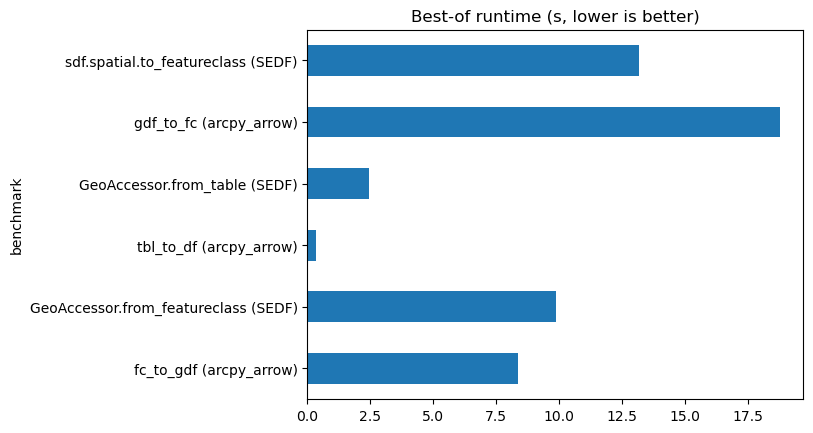

In [8]:
summary.set_index("benchmark")["best_s"].plot.barh(title="Best-of runtime (s, lower is better)")